# Asistente de IA para la planificación docente — Experimento ML
**Proyecto UFHEC · Aprendizaje Automático**  
**Advertencia:** Datos 100 % sintéticos, etiquetas definidas mediante reglas pedagógicas simplificadas. Los resultados miden la reproducción de estas reglas, **no** validan la utilidad real en las aulas. Se requiere evaluación con expertos y datos autorizados.

## 1. Objetivo
Clasificar una estrategia pedagógica recomendada a partir de atributos de una solicitud docente. Compararemos regresión logística y Random Forest con validación cruzada en el conjunto de entrenamiento y evaluación final en un conjunto separado.

In [1]:
import pandas as pd, numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score
import matplotlib.pyplot as plt, joblib

## 2. Cargar datos
Desde GitHub: el CSV está en `data/`. En Google Colab, sube el CSV si no encuentras el archivo local.

In [2]:
archivo=Path('data/escenarios_sinteticos.csv')
if not archivo.exists():
    archivo=Path('escenarios_sinteticos.csv')
assert archivo.exists(), 'Sube escenarios_sinteticos.csv a Colab o ejecuta desde la raíz del repositorio'
df=pd.read_csv(archivo)
print('Filas y columnas:',df.shape)
display(df.head())

Filas y columnas: (480, 8)


,id_escenario,nivel,asignatura,necesidad,tipo_contenido,recursos,duracion_min,estrategia
0,SIN-0001,Primaria,Matemáticas,Refuerzo,Conceptual,Básicos,45,Práctica guiada
1,SIN-0002,Secundaria,Matemáticas,Refuerzo,Conceptual,Básicos,45,Práctica guiada
2,SIN-0003,Superior,Matemáticas,Refuerzo,Conceptual,Básicos,45,Práctica guiada
3,SIN-0004,Primaria,Lengua Española,Refuerzo,Conceptual,Básicos,45,Práctica guiada
4,SIN-0005,Secundaria,Lengua Española,Refuerzo,Conceptual,Básicos,45,Práctica guiada


## 3. Calidad y exploración de datos (EDA)

Nulos por columna:


,nulos
id_escenario,0
nivel,0
asignatura,0
necesidad,0
tipo_contenido,0
recursos,0
duracion_min,0
estrategia,0


Duplicados exactos: 0


,frecuencia
estrategia,
Práctica guiada,120
Aprendizaje cooperativo,120
Aprendizaje basado en problemas,120
Proyecto de profundización,120


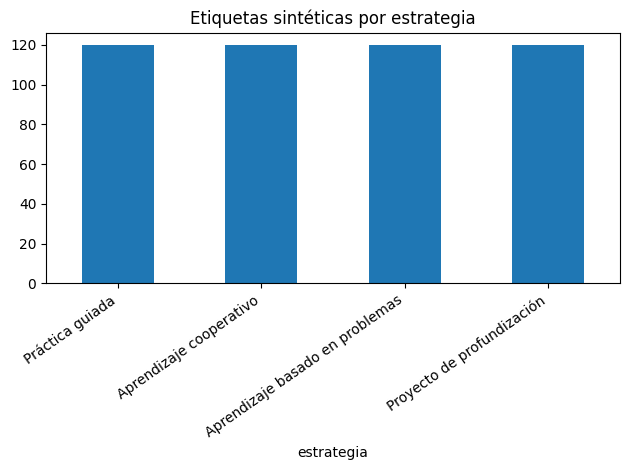

In [3]:
print('Nulos por columna:')
display(df.isna().sum().to_frame('nulos'))
print('Duplicados exactos:',df.duplicated().sum())
display(df['estrategia'].value_counts().to_frame('frecuencia'))
df['estrategia'].value_counts().plot.bar(title='Etiquetas sintéticas por estrategia');plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.show()

## 4. Variables, partición y preprocesamiento
Se excluye el identificador `id_escenario`. La división estratificada es 75 % entrenamiento y 25 % prueba. La validación cruzada ocurre únicamente en entrenamiento.

In [4]:
columnas=['nivel','asignatura','necesidad','tipo_contenido','recursos','duracion_min']
categoricas=columnas[:-1]
X=df[columnas];y=df['estrategia']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
print('Entrenamiento:',len(X_train),'Prueba:',len(X_test))
def crear_pipeline(clasificador):
 return Pipeline([('preprocesado',ColumnTransformer([('categoricas',OneHotEncoder(handle_unknown='ignore'),categoricas),('numericas','passthrough',['duracion_min'])])),('clasificador',clasificador)])

Entrenamiento: 360 Prueba: 120


## 5. Entrenar y comparar modelos
Los números de las métricas deben calcularse al ejecutar este notebook; no se ingresan manualmente.

In [5]:
candidatos={'Regresión logística':LogisticRegression(max_iter=1500),'Random Forest':RandomForestClassifier(n_estimators=120,min_samples_leaf=2,random_state=42)}
filas=[]
for nombre,estimador in candidatos.items():
    m=crear_pipeline(estimador)
    resultado=cross_validate(m,X_train,y_train,cv=StratifiedKFold(5,shuffle=True,random_state=42),scoring={'f1_macro':'f1_macro','accuracy':'accuracy'})
    m.fit(X_train,y_train)
    pred=m.predict(X_test)
    filas.append({'modelo':nombre,'cv_F1_macro':resultado['test_f1_macro'].mean(),'accuracy_prueba':accuracy_score(y_test,pred),'F1_macro_prueba':f1_score(y_test,pred,average='macro')})
comparacion=pd.DataFrame(filas).sort_values('cv_F1_macro',ascending=False)
display(comparacion)

,modelo,cv_F1_macro,accuracy_prueba,F1_macro_prueba
0,Regresión logística,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0


## 6. Evaluación del modelo elegido
La selección se basa en el F1-macro de validación cruzada, no en el conjunto de prueba.

Seleccionado: Random Forest
                                 precision    recall  f1-score   support

Aprendizaje basado en problemas       1.00      1.00      1.00        30
        Aprendizaje cooperativo       1.00      1.00      1.00        30
     Proyecto de profundización       1.00      1.00      1.00        30
                Práctica guiada       1.00      1.00      1.00        30

                       accuracy                           1.00       120
                      macro avg       1.00      1.00      1.00       120
                   weighted avg       1.00      1.00      1.00       120



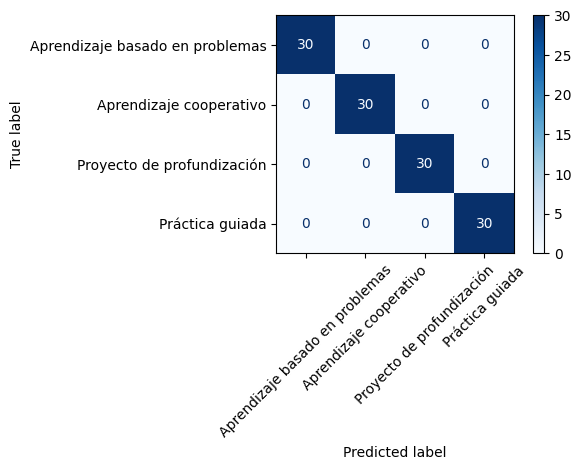

In [6]:
# Ante empate en la métrica, usar Random Forest para mantener reproducibilidad con la app.
mejor='Random Forest' if 'Random Forest' in comparacion.loc[comparacion.cv_F1_macro==comparacion.cv_F1_macro.max(),'modelo'].values else comparacion.iloc[0]['modelo']
modelo=crear_pipeline(candidatos[mejor]);modelo.fit(X_train,y_train);pred=modelo.predict(X_test)
print('Seleccionado:',mejor)
print(classification_report(y_test,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred,xticks_rotation=45,cmap='Blues');plt.tight_layout();plt.show()

## 7. Prueba con un escenario de planificación docente

In [7]:
ejemplo=pd.DataFrame([{'nivel':'Primaria','asignatura':'Matemáticas','necesidad':'Refuerzo','tipo_contenido':'Conceptual','recursos':'Manipulativos','duracion_min':45}])
print('Estrategia propuesta:',modelo.predict(ejemplo)[0])

Estrategia propuesta: Práctica guiada


## 8. Guardar modelo y limitaciones
El archivo `.joblib` debe cargarse únicamente desde una fuente confiable. La aplicación de Streamlit lo utilizará para inferencias. Una puntuación alta con etiquetas sintéticas no garantiza efectividad pedagógica real.

In [8]:
Path('modelos').mkdir(exist_ok=True)
joblib.dump(modelo,'modelos/clasificador_estrategias.joblib')
print('Modelo guardado en modelos/clasificador_estrategias.joblib')

Modelo guardado en modelos/clasificador_estrategias.joblib


## Conclusión
Este ejercicio verifica un flujo técnico de clasificación y métricas sobre escenarios sintéticos. Trabajo futuro: obtener autorizaciones, diseñar rúbrica de etiquetado, revisar casos con docentes, prevenir fuga entre escenarios relacionados y comparar la calidad de las recomendaciones por nivel y asignatura.